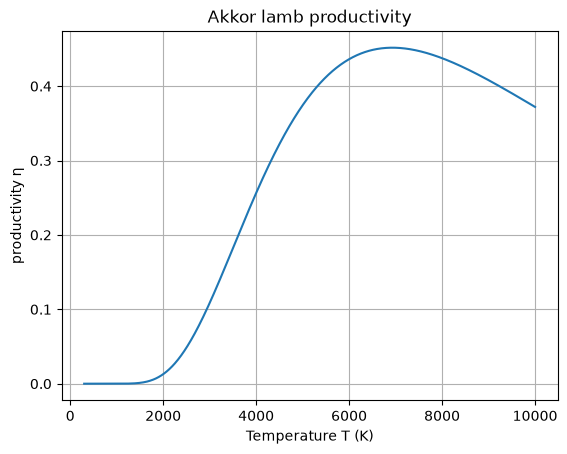

In [4]:
# a
import numpy as np
import pylab as plt

# constants
h = 6.62e-34    # Planck constant
c = 3e8         # speed of light
K_B = 1.38e-23  # Boltzmann constant
constants = h*c/K_B
lambda1 = 390e-9
lambda2 = 750e-9


def integrand(x):
    return x**3 / (np.exp(x) - 1)


def eta(T):
    b = constants /  (lambda1 * T)
    a = constants /  (lambda2 * T)
    N = 100
    x_standard, w_standard = np.polynomial.legendre.leggauss(N)

    # mapping
    xp = 0.5 * (b-a) * x_standard + 0.5 * (b+a)
    wp = 0.5 * (b-a) * w_standard
    return 15/np.pi**4 * (wp*integrand(xp)).sum()

T_values = np.linspace(300, 10000, 1000)
eta_values = np.zeros(len(T_values))
for i in range(len(T_values)):
    eta_values[i] = eta(T_values[i])

# graph
plt.plot(T_values, eta_values)
plt.xlabel("Temperature T (K)")
plt.ylabel("productivity η")
plt.title("Akkor lamb productivity")
plt.grid(True)
plt.savefig("productivity.png", dpi=120)
plt.show()



In [5]:
# b
def f(T):
    return -eta(T)
 
z = (1 + np.sqrt(5))/2     # golden ratio
accuracy = 1.0          # target precision: 1 K
 
# Starting range: the graph shows that the peak lies between 5000 and 9000 K
x1 = 5000.0
x4 = 9000.0
x2 = x4 - (x4 - x1)/z
x3 = x1 + (x4 - x1)/z
 
f1 = f(x1)
f2 = f(x2)
f3 = f(x3)
f4 = f(x4)
 
# Check that the range actually includes the minimum
if min(f2, f3) >= min(f1, f4):
    print("Warning: the start range might not include the maximum value!")
 
while x4 - x1 > accuracy:
    if f2 < f3:
        x4, f4 = x3, f3
        x3, f3 = x2, f2
        x2 = x4 - (x4 - x1)/z
        f2 = f(x2)
    else:
        x1, f1 = x2, f2
        x2, f2 = x3, f3
        x3 = x1 + (x4 - x1)/z
        f3 = f(x3)
 
T_max = 0.5*(x1 + x4)
print("(b) Temperature for maximum efficiency: %.0f K" % T_max)
print("    Efficiency at this temperature:    %.4f (%%%.1f)" % (eta(T_max), 100*eta(T_max)))

(b) Temperature for maximum efficiency: 6930 K
    Efficiency at this temperature:    0.4517 (%45.2)
